# **Detección de spam en SMS con redes recurrentes**

Comparación de tres arquitecturas recurrentes (SimpleRNN, LSTM y GRU, construidas con la *Functional API* de Keras) para clasificar mensajes SMS en `ham` (normal) o `spam`, con el conjunto *SMS Spam Collection* de UCI. El problema está desbalanceado (≈ 13 % de spam), por lo que se usan pesos de clase y métricas distintas de la exactitud.

**Flujo:** carga y división estratificada · tokenización · elección de `MAXLEN` · pesos de clase · tres arquitecturas · ajuste de hiperparámetros con Keras Tuner · *callbacks* · selección en validación · evaluación única en prueba · análisis de errores.


## 1. Librerías básicas y reproducibilidad


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import urllib.request
import zipfile

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0


## 2. Carga del dataset


In [ ]:
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
urllib.request.urlretrieve(url, "sms_spam.zip")

with zipfile.ZipFile("sms_spam.zip", "r") as zip_ref:
    zip_ref.extractall("sms_spam")

df = pd.read_csv(
    "sms_spam/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "text"]
)

display(df.head())

print("Dimensión:", df.shape)

print("\nValores faltantes:")
print(df.isna().sum())

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Dimensión: (5572, 2)

Valores faltantes:
label    0
text     0
dtype: int64


## 3. Exploración inicial


In [ ]:
display(df.sample(10, random_state=SEED))

print("\nDistribución de clases:")
display(df["label"].value_counts())

print("\nProporciones:")
display(df["label"].value_counts(normalize=True))

,label,text
3245,ham,Squeeeeeze!! This is christmas hug.. If u lik ...
944,ham,And also I've sorta blown him off a couple tim...
1044,ham,Mmm thats better now i got a roast down me! i...
2484,ham,Mm have some kanji dont eat anything heavy ok
812,ham,So there's a ring that comes with the guys cos...
2973,ham,Sary just need Tim in the bollox &it hurt him ...
2991,ham,"Love isn't a decision, it's a feeling. If we c..."
2942,ham,My supervisor find 4 me one lor i thk his stud...
230,ham,Dear good morning now only i am up
1181,ham,I'm in chennai velachery:)



Distribución de clases:


,count
label,
ham,4825
spam,747



Proporciones:


,proportion
label,
ham,0.865937
spam,0.134063


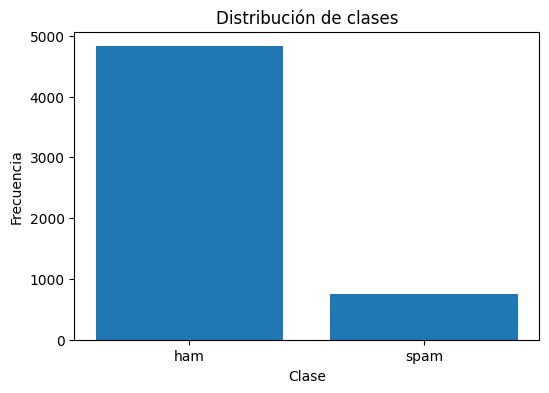

In [ ]:
class_counts = df["label"].value_counts()

plt.figure(figsize=(6,4))
plt.bar(class_counts.index, class_counts.values)
plt.xlabel("Clase")
plt.ylabel("Frecuencia")
plt.title("Distribución de clases")
plt.show()

### Observación

La distribución de las clases no es uniforme, lo que se tiene en cuenta en el entrenamiento y en la evaluación.


## 4. Codificación de la variable respuesta


In [ ]:
df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

display(df.head())

,label,text,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 5. División en entrenamiento, validación y prueba


In [ ]:
X_text = df["text"].astype(str).values
y_all = df["label_num"].values

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y_all,
    test_size=0.20,
    stratify=y_all,
    random_state=SEED
)

X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_train_text,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=SEED
)

print("Train:", len(X_train_text))
print("Validation:", len(X_val_text))
print("Test:", len(X_test_text))

Train: 3565
Validation: 892
Test: 1115


## 6. Tokenización

Se utiliza el procedimiento estándar de Keras:

```python
Tokenizer
fit_on_texts
texts_to_sequences
```

El vocabulario se ajusta únicamente con los datos de entrenamiento.

In [ ]:
VOCAB_SIZE = 5000

tokenizer = Tokenizer(
    num_words=VOCAB_SIZE
)

tokenizer.fit_on_texts(X_train_text)

train_sequences = tokenizer.texts_to_sequences(X_train_text)
val_sequences = tokenizer.texts_to_sequences(X_val_text)
test_sequences = tokenizer.texts_to_sequences(X_test_text)

print("Ejemplo de texto:")
print(X_train_text[0])

print("\nEjemplo tokenizado:")
print(train_sequences[0])

Ejemplo de texto:
That sucks. So what do you got planned for your yo valentine? I am your yo valentine aren't I?

Ejemplo tokenizado:
[20, 938, 23, 54, 26, 3, 55, 1218, 12, 13, 329, 1066, 1, 58, 13, 329, 1066, 1219, 1]


## 7. Longitud de los mensajes


Media:        15.17
Mediana:      12.00
Percentil 95: 32.00
Máximo:       121


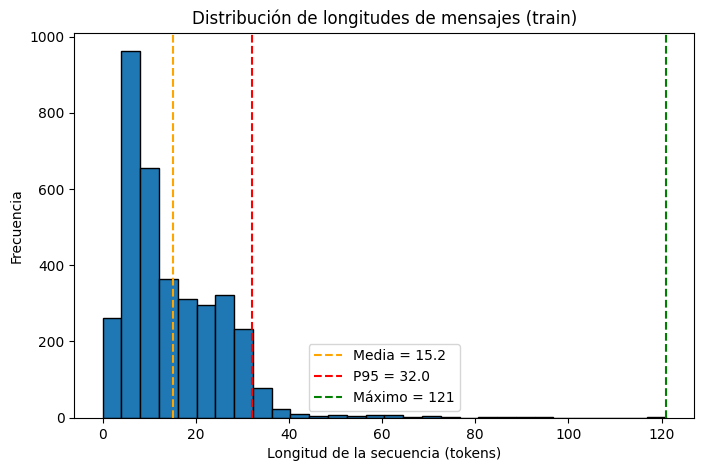

In [ ]:
# Longitudes de las secuencias tokenizadas (conjunto de entrenamiento)
lengths = [len(seq) for seq in train_sequences]
lengths = np.array(lengths)

media = lengths.mean()
mediana = np.median(lengths)
p95 = np.percentile(lengths, 95)
maximo = lengths.max()

print(f"Media:        {media:.2f}")
print(f"Mediana:      {mediana:.2f}")
print(f"Percentil 95: {p95:.2f}")
print(f"Máximo:       {maximo}")

plt.figure(figsize=(8, 5))
plt.hist(lengths, bins=30, edgecolor="black")
plt.axvline(media, color="orange", linestyle="--", label=f"Media = {media:.1f}")
plt.axvline(p95, color="red", linestyle="--", label=f"P95 = {p95:.1f}")
plt.axvline(maximo, color="green", linestyle="--", label=f"Máximo = {maximo}")
plt.xlabel("Longitud de la secuencia (tokens)")
plt.ylabel("Frecuencia")
plt.title("Distribución de longitudes de mensajes (train)")
plt.legend()
plt.show()

Se selecciona el percentil 95 como longitud máxima (`MAXLEN`) de las secuencias, con base en el análisis de la distribución de longitudes del conjunto de entrenamiento. Esta decisión responde a dos criterios complementarios: por un lado, el percentil 95 cubre la gran mayoría de los mensajes reales sin sacrificar representatividad; por otro, evita que valores atípicos —mensajes inusualmente largos que representan menos del 5% del corpus— impongan una longitud máxima que generaría *padding* excesivo en el resto de las secuencias. Dado que los SMS son por naturaleza mensajes concisos, la longitud del mensaje más largo no refleja el comportamiento típico del texto en esta tarea. Utilizar ese máximo absoluto inflaría innecesariamente la dimensión temporal de cada secuencia, aumentando el costo computacional del entrenamiento sin aportar información discriminativa relevante para la clasificación.

## 8. Padding


In [ ]:
X_train = pad_sequences(
    train_sequences,
    maxlen=maxim,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    val_sequences,
    maxlen=maxim,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    test_sequences,
    maxlen=maxim,
    padding="post",
    truncating="post"
)

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)

X_train: (3565, 32)
X_val:   (892, 32)
X_test:  (1115, 32)


Se aplica `pad_sequences` a los tres conjuntos utilizando el `MAXLEN` definido en la sección anterior, garantizando que todas las secuencias tengan dimensiones compatibles con las capas recurrentes. Se elige `padding="post"` y `truncating="post"` por dos razones: primero, agregar los ceros al final preserva el inicio del mensaje, que concentra la mayor parte de la información semántica relevante en textos cortos como los SMS; segundo, truncar también por el final descarta los tokens excedentes que quedan al final de los mensajes más largos, manteniendo el contexto inicial intacto. Aplicar el mismo `MAXLEN` a entrenamiento, validación y prueba es un requisito técnico indispensable: las capas `Embedding` y las celdas recurrentes esperan tensores de forma fija `(None, MAXLEN)`, y cualquier inconsistencia entre conjuntos produciría un error en tiempo de inferencia.

## 9. Tratamiento del desbalance


In [ ]:
from sklearn.utils import class_weight

# Distribución de clases en el conjunto de entrenamiento
train_counts = pd.Series(y_train).value_counts().sort_index()
train_props = pd.Series(y_train).value_counts(normalize=True).sort_index()

print("Conteo de clases en train:")
print(train_counts)
print("\nProporción de clases en train:")
print(train_props)

# Cálculo de pesos de clase (balanceados) usando SOLO el conjunto de entrenamiento
class_weights_array = class_weight.compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(enumerate(class_weights_array))
print("\nPesos de clase:", class_weights)

Conteo de clases en train:
0    3087
1     478
Name: count, dtype: int64

Proporción de clases en train:
0    0.865919
1    0.134081
Name: proportion, dtype: float64

Pesos de clase: {0: np.float64(0.5774214447683835), 1: np.float64(3.7290794979079496)}


1. El desbalance existe porque la naturaleza del problema lo impone: en cualquier bandeja de SMS real, la clase *ham* es ampliamente mayoritaria (~ 87%) y el *spam* representa una fracción pequeña (~ 13%). El dataset refleja esa proporción real, por lo que el desbalance no es un artefacto del muestreo sino una característica inherente del fenómeno.

2. Con clases desbalanceadas, un modelo que prediga siempre *ham* alcanzaría una accuracy de ~87% sin haber aprendido nada útil. La accuracy asume que todos los errores tienen el mismo costo, lo cual es falso aquí: clasificar un spam como *ham* (falso negativo) es más costoso que el error contrario, y esa asimetría no queda recogida en la accuracy.

3. Al usar `class_weight`, el optimizador penaliza más fuertemente los errores sobre la clase minoritaria durante el entrenamiento. Esto obliga al modelo a prestar mayor atención a los ejemplos de spam, mejorando el **Recall** de esa clase y reduciendo los falsos negativos, aunque puede traducirse en una leve caída de accuracy global al aumentar marginalmente los falsos positivos.

4. Los pesos de clase deben calcularse exclusivamente sobre el conjunto de entrenamiento porque validación y prueba deben permanecer completamente ajenos al proceso de ajuste del modelo. Si se incluyeran esos conjuntos en el cálculo, se estaría filtrando información de su distribución hacia el entrenamiento, lo que inflaría artificialmente las métricas y rompería la separación necesaria para una evaluación honesta de la generalización.



## 10. Arquitecturas


In [ ]:
embed_dim = 64
rnnu = 64
droprate = 0.3
learningrt = 0.001

print("Longitud máxima:", maxim)
print("Dim:", embed_dim)
print("Unidades Rnn:", rnnu)
print("Dropout:", droprate)
print("Learning rate:", learningrt)

Longitud máxima: 32
Dim: 64
Unidades Rnn: 64
Dropout: 0.3
Learning rate: 0.001


Los hiperparámetros base se fijaron de la siguiente manera antes de iniciar el entrenamiento:

- **`embed_dim = 64` y `rnnu = 64`:** Se utiliza la misma dimensión tanto para el *embedding* como para las unidades recurrentes con el propósito de mantener condiciones comparables entre las tres arquitecturas (SimpleRNN, LSTM, GRU). Un valor de 64 es suficientemente expresivo para capturar representaciones semánticas en un vocabulario de 5.000 tokens, sin sobreparametrizar modelos que en su núcleo son arquitecturas relativamente simples.

- **`dropout = 0.3`:** Se aplica una capa de *Dropout* con tasa 0.3 después de la capa recurrente en los tres modelos. Esta tasa desactiva aleatoriamente el 30% de las neuronas en cada paso de entrenamiento, actuando como regularizador explícito y reduciendo el riesgo de sobreajuste sin degradar excesivamente la capacidad de aprendizaje.

- **`learning_rate = 0.001`:** Corresponde al valor estándar del optimizador Adam y representa un balance probado entre velocidad de convergencia y estabilidad. Para un dataset de tamaño moderado como este (~5.500 mensajes), tasas más altas pueden generar oscilaciones en la pérdida, mientras que tasas más bajas alargarían innecesariamente el entrenamiento. Este valor además manes una configuración estándar, lo que facilita la reproducibilidad y comparación de resultados.

## 11. Primera arquitectura — SimpleRNN


In [ ]:
from tensorflow.keras import Input
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.models import Model

inputs_rnn = Input(shape=(maxim,), name="input_tokens")
x = Embedding(input_dim=VOCAB_SIZE, output_dim=embed_dim, name="embedding")(inputs_rnn)
x = SimpleRNN(rnnu, name="simple_rnn")(x)
x = Dropout(droprate, name="dropout")(x)
outputs_rnn = Dense(1, activation="sigmoid", name="output")(x)

model_rnn = Model(inputs=inputs_rnn, outputs=outputs_rnn, name="SimpleRNN_model")

model_rnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=learningrt),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

model_rnn.summary()

Model: "SimpleRNN_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_tokens (InputLayer)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 32, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,321 (1.25 MB)

 Trainable params: 328,321 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

Las decisiones de compilación se justifican de la siguiente manera:

- **Activación de salida `sigmoid`:** Al tratarse de un problema de clasificación binaria (*ham* vs. *spam*), la capa de salida tiene una única neurona con activación sigmoide, que mapea la salida del modelo al intervalo (0, 1) e interpreta el resultado como la probabilidad de que el mensaje pertenezca a la clase *spam*. El umbral de decisión se fija en 0.5.

- **Función de pérdida `binary_crossentropy`:** Es la función de pérdida canónica para clasificación binaria con salida sigmoide. Penaliza de forma logarítmica las predicciones de probabilidad alejadas de la etiqueta real, lo que produce gradientes informativos a lo largo de todo el entrenamiento y es matemáticamente coherente con la salida probabilística del modelo.

- **Optimizador `Adam`:** Adam combina momentum y tasas de aprendizaje adaptativas por parámetro, lo que lo hace más robusto que SGD puro en problemas con gradientes ruidosos o datos desbalanceados. No requiere un ajuste fino manual del *learning rate* en cada capa, y converge de forma más eficiente con la configuración estándar (`lr=0.001`).

- **Métricas adicionales `Precision` y `Recall`:** Dado el desbalance entre clases, monitorear únicamente accuracy durante el entrenamiento sería insuficiente para detectar si el modelo está ignorando la clase *spam*. Incluir Precision y Recall permite observar en tiempo real si el modelo efectivamente aprende a identificar mensajes no deseados, y no solo a clasificar correctamente la clase mayoritaria.

## 12. Segunda arquitectura — LSTM


In [ ]:
from tensorflow.keras import Input
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.models import Model

inputs_lstm = Input(shape=(maxim,), name="input_tokens")
x = Embedding(input_dim=VOCAB_SIZE, output_dim=embed_dim, name="embedding")(inputs_lstm)
x = LSTM(rnnu, name="lstm")(x)
x = Dropout(droprate, name="dropout")(x)
outputs_lstm = Dense(1, activation="sigmoid", name="output")(x)

model_lstm = Model(inputs=inputs_lstm, outputs=outputs_lstm, name="LSTM_model")

model_lstm.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=learningrt),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

model_lstm.summary()

Model: "LSTM_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_tokens (InputLayer)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 32, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353,089 (1.35 MB)

 Trainable params: 353,089 (1.35 MB)

 Non-trainable params: 0 (0.00 B)

## 13. Tercera arquitectura — GRU


In [ ]:
from tensorflow.keras import Input
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout
from tensorflow.keras.models import Model

inputs_gru = Input(shape=(maxim,), name="input_tokens")
x = Embedding(input_dim=VOCAB_SIZE, output_dim=embed_dim, name="embedding")(inputs_gru)
x = GRU(rnnu, name="gru")(x)
x = Dropout(droprate, name="dropout")(x)
outputs_gru = Dense(1, activation="sigmoid", name="output")(x)

model_gru = Model(inputs=inputs_gru, outputs=outputs_gru, name="GRU_model")

model_gru.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=learningrt),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
    ],
)

model_gru.summary()

Model: "GRU_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_tokens (InputLayer)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 32, 64)         │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 345,025 (1.32 MB)

 Trainable params: 345,025 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

## 14. Keras Tuner


In [ ]:
!pip install keras-tuner -q
import keras_tuner as kt

def build_model_tuner(hp):
    hp_units = hp.Int("units", min_value=32, max_value=128, step=32)
    hp_dropout = hp.Float("dropout_rate", min_value=0.1, max_value=0.5, step=0.1)

    inputs_tuner = Input(shape=(maxim,), name="input_tokens")
    x = Embedding(input_dim=VOCAB_SIZE, output_dim=embed_dim, name="embedding")(inputs_tuner)
    x = LSTM(hp_units, name="lstm")(x)
    x = Dropout(hp_dropout, name="dropout")(x)
    outputs_tuner = Dense(1, activation="sigmoid", name="output")(x)

    model_tuner = Model(inputs=inputs_tuner, outputs=outputs_tuner)
    model_tuner.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=learningrt),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model_tuner

tuner = kt.Hyperband(
    build_model_tuner,
    objective="val_loss",
    max_epochs=10,
    factor=3,
    directory="kt_dir",
    project_name="sms_spam_lstm_tuning",
)

tuner.search(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    class_weight=class_weights,
    callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3)],
)

best_hp = tuner.get_best_hyperparameters(1)[0]
print("Mejor número de unidades:", best_hp.get("units"))
print("Mejor dropout_rate:", best_hp.get("dropout_rate"))

best_model_tuned = tuner.hypermodel.build(best_hp)

Trial 28 Complete [00h 00m 23s]
val_loss: 0.09521372616291046

Best val_loss So Far: 0.06166543811559677
Total elapsed time: 00h 07m 28s
Mejor número de unidades: 96
Mejor dropout_rate: 0.2


Se aplica Keras Tuner sobre la arquitectura **LSTM**, por ser el modelo de complejidad intermedia entre SimpleRNN y GRU, lo que la convierte en la candidata más representativa para explorar el espacio de hiperparámetros.

**Hiperparámetros ajustados:**

- **`units` (unidades recurrentes):** Controla directamente la capacidad del modelo para aprender representaciones. Un valor demasiado bajo limita el aprendizaje; uno demasiado alto sobreparametriza. Se exploró el rango [32, 128] en pasos de 32.
- **`dropout_rate`:** Es el principal mecanismo de regularización del modelo. Su interacción con la cantidad de unidades es relevante: más unidades pueden requerir mayor dropout. Se exploró el rango [0.1, 0.5] en pasos de 0.1.

Se fijaron los demás hiperparámetros (`embed_dim`, `learning_rate`) para mantener la comparabilidad con los modelos entrenados en las secciones anteriores.

**Estrategia de búsqueda — Hyperband:** Se eligió Hyperband por su eficiencia computacional: asigna más recursos a las configuraciones prometedoras y descarta tempranamente las de bajo desempeño, reduciendo el tiempo total de búsqueda frente a un grid search o random search exhaustivo.

**Espacio de búsqueda:**

| Hiperparámetro | Mínimo | Máximo | Paso |
|---|---|---|---|
| `units` | 32 | 128 | 32 |
| `dropout_rate` | 0.1 | 0.5 | 0.1 |

**Mejor combinación encontrada:**

| Hiperparámetro | Mejor valor |
|---|---|
| `units` | 96 |
| `dropout_rate` | 0.2 |

**Desempeño del mejor modelo:** La combinación óptima alcanzó un `val_loss` de **0.0617**, el valor más bajo registrado en toda la búsqueda, lo que indica que 96 unidades con un dropout de 0.2 logra el mejor equilibrio entre capacidad expresiva y regularización para este dataset.

## 15. Callbacks


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

def get_callbacks(model_name):
    return [
        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6
        ),
        ModelCheckpoint(
            filepath=f"best_{model_name}.keras",
            monitor="val_loss",
            save_best_only=True
        ),
    ]

Los tres *callbacks* se configuraron de la siguiente manera y por las siguientes razones:

- **Variable monitorizada — `val_loss`:** Se prefiere `val_loss` sobre `val_accuracy` porque la pérdida es una señal continua y más sensible a cambios pequeños en el comportamiento del modelo. La accuracy, en cambio, es discreta y puede permanecer estancada durante varias épocas aunque el modelo esté mejorando internamente, especialmente con clases desbalanceadas donde pequeñas variaciones en probabilidades no siempre se traducen en cambios de la predicción final.

- **`EarlyStopping` — `patience=3`:** Una paciencia de 3 épocas permite al modelo atravesar pequeñas mesetas temporales sin detenerse prematuramente, pero es lo suficientemente corta para interrumpir el entrenamiento antes de que el sobreajuste se consolide. Con `restore_best_weights=True`, los pesos recuperados corresponden siempre a la época de menor `val_loss`, no a la última.

- **`ReduceLROnPlateau` — `factor=0.5`, `patience=2`, `min_lr=1e-6`:** Cuando `val_loss` no mejora durante 2 épocas consecutivas, el *learning rate* se reduce a la mitad. Un factor de 0.5 produce una reducción gradual y controlada que permite al optimizador afinar los pesos cerca de un mínimo sin dar saltos bruscos. El límite inferior de `1e-6` evita que la tasa de aprendizaje colapse a valores prácticamente nulos que paralicen el entrenamiento.

- **`ModelCheckpoint` — `save_best_only=True`:** Se guarda únicamente el modelo correspondiente a la época con menor `val_loss`. Usar la misma variable que los demás *callbacks* garantiza coherencia: el modelo guardado es exactamente el que `EarlyStopping` y `ReduceLROnPlateau` consideran óptimo, evitando que se conserve una versión posterior con mayor sobreajuste.

## 16. Entrenamiento de los modelos


In [ ]:
epocas = 20
tam_lote = 32

print("SimpleRNN")
history_rnn = model_rnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=epocas,
    batch_size=tam_lote,
    class_weight=class_weights,
    callbacks=get_callbacks("simplernn"),
    verbose=1
)

print("LSTM")
history_lstm = model_lstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=epocas,
    batch_size=tam_lote,
    class_weight=class_weights,
    callbacks=get_callbacks("lstm"),
    verbose=1
)

print("GRU")
history_gru = model_gru.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=epocas,
    batch_size=tam_lote,
    class_weight=class_weights,
    callbacks=get_callbacks("gru"),
    verbose=1
)

histories = {
    "SimpleRNN": history_rnn,
    "LSTM": history_lstm,
    "GRU": history_gru,
}

SimpleRNN
Epoch 1/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9854 - loss: 0.0805 - precision: 0.9243 - recall: 0.9707 - val_accuracy: 0.9283 - val_loss: 0.2025 - val_precision: 0.6667 - val_recall: 0.9333 - learning_rate: 0.0010
Epoch 2/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9860 - loss: 0.0714 - precision: 0.9213 - recall: 0.9791 - val_accuracy: 0.9765 - val_loss: 0.1012 - val_precision: 0.9901 - val_recall: 0.8333 - learning_rate: 0.0010
Epoch 3/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9902 - loss: 0.0495 - precision: 0.9421 - recall: 0.9874 - val_accuracy: 0.9608 - val_loss: 0.1655 - val_precision: 0.8346 - val_recall: 0.8833 - learning_rate: 0.0010
Epoch 4/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9896 - loss: 0.0619 - precision: 0.9419 - recall: 0.9833 - val_accuracy: 0.9731 - val_loss: 0.1135 - val_precision: 0.9211 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 5/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/st

## 17. Métricas


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

modelos = {
    "SimpleRNN": model_rnn,
    "LSTM": model_lstm,
    "GRU": model_gru,
}

resultados = []

for nombre, modelo in modelos.items():
    y_val_prob = modelo.predict(X_val)
    y_val_pred = (y_val_prob > 0.5).astype(int).ravel()

    acc = accuracy_score(y_val, y_val_pred)
    prec = precision_score(y_val, y_val_pred)
    rec = recall_score(y_val, y_val_pred)
    f1 = f1_score(y_val, y_val_pred)

    resultados.append({
        "Modelo": nombre,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
    })

tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados)

28/28 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step


,Modelo,Accuracy,Precision,Recall,F1
0,SimpleRNN,0.976457,0.990099,0.833333,0.904977
1,LSTM,0.979821,1.000000,0.850000,0.918919
2,GRU,0.984305,0.973214,0.908333,0.939655


La métrica más relevante para este problema es el **F1-score**, por las siguientes razones:

- **Limitación de Accuracy:** Como se discutió en la sección de desbalance, un modelo que prediga siempre *ham* obtendría ~87% de accuracy sin haber detectado un solo mensaje de spam. Accuracy no es una métrica confiable cuando las clases están desbalanceadas.

- **Limitación de Precision aislada:** Un modelo con Precision perfecta podría ser extremadamente conservador, clasificando como spam únicamente los casos más obvios y dejando pasar la mayoría de mensajes no deseados (alto número de falsos negativos).

- **Limitación de Recall aislado:** Un modelo optimizado exclusivamente para Recall tendería a clasificar todo como spam para no perder ningún caso positivo, generando una cantidad inaceptable de falsos positivos y bloqueando mensajes legítimos.

- **F1 como síntesis:** El F1-score es la media armónica entre Precision y Recall, lo que lo convierte en una métrica que penaliza los desequilibrios extremos entre ambas. Un modelo solo alcanza un F1 alto si logra simultáneamente detectar la mayoría de los spams *y* evitar clasificar mensajes legítimos como spam. Por esa razón es el criterio más honesto para comparar las tres arquitecturas en este contexto.

- **Recall como alternativa válida:** En un escenario donde el costo de recibir spam sea considerablemente mayor que el de bloquear un mensaje legítimo, priorizar Recall sería justificable. Sin embargo, para una evaluación general y equilibrada del clasificador, F1 es la métrica más adecuada.

## 18. Curvas de entrenamiento


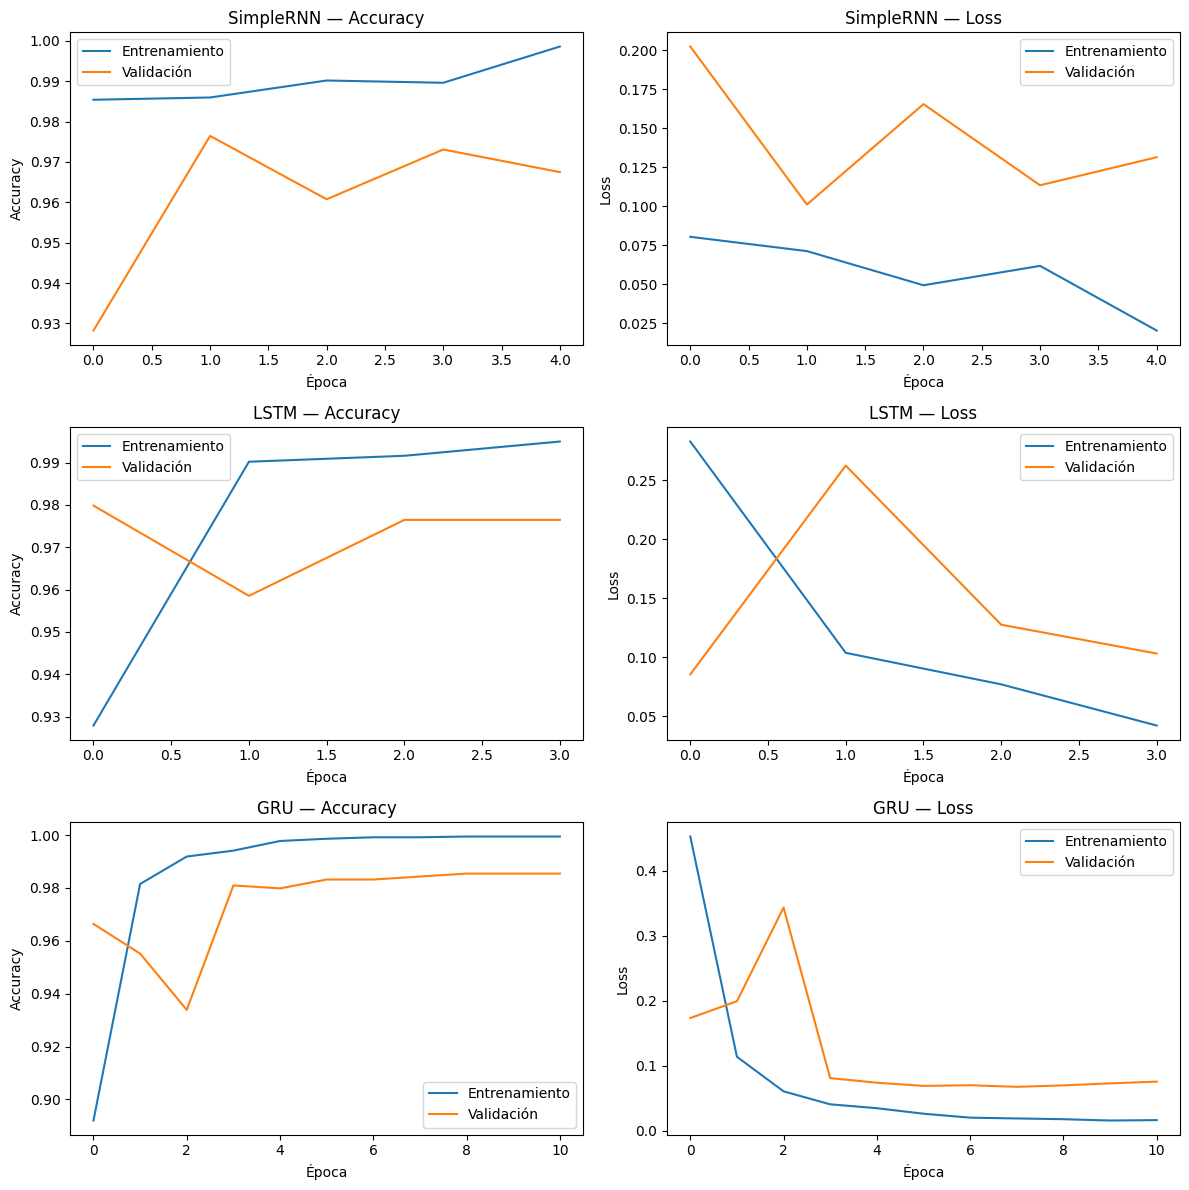

In [ ]:
fig, axes = plt.subplots(len(histories), 2, figsize=(12, 4 * len(histories)))

for i, (nombre, hist) in enumerate(histories.items()):
    # Accuracy
    axes[i, 0].plot(hist.history["accuracy"], label="Entrenamiento")
    axes[i, 0].plot(hist.history["val_accuracy"], label="Validación")
    axes[i, 0].set_title(f"{nombre} — Accuracy")
    axes[i, 0].set_xlabel("Época")
    axes[i, 0].set_ylabel("Accuracy")
    axes[i, 0].legend()

    # Loss
    axes[i, 1].plot(hist.history["loss"], label="Entrenamiento")
    axes[i, 1].plot(hist.history["val_loss"], label="Validación")
    axes[i, 1].set_title(f"{nombre} — Loss")
    axes[i, 1].set_xlabel("Época")
    axes[i, 1].set_ylabel("Loss")
    axes[i, 1].legend()

plt.tight_layout()
plt.show()

El análisis de las curvas de entrenamiento revela comportamientos diferenciados entre las tres arquitecturas:

- **SimpleRNN:** Las curvas de *loss* de entrenamiento y validación presentan una brecha considerable y sostenida a lo largo de las épocas, acompañada de oscilaciones marcadas en la curva de validación. Esta combinación es el patrón clásico de **sobreajuste**: el modelo memoriza el conjunto de entrenamiento pero no generaliza correctamente a datos nuevos. La inestabilidad en `val_loss` sugiere además que SimpleRNN es sensible al orden de los ejemplos y a la naturaleza ruidosa del texto SMS, lo cual es consistente con su limitación estructural para capturar dependencias de largo alcance.

- **LSTM:** Tanto la curva de *loss* como la de *accuracy* de entrenamiento y validación convergen de forma paralela y sin oscilaciones relevantes. No se observan señales de sobreajuste ni de subajuste. La convergencia es progresiva y estable, lo que indica que el modelo aprendió representaciones generalizables gracias a sus compuertas de memoria.

- **GRU:** Presenta el comportamiento más óptimo de los tres modelos. Sus curvas de entrenamiento y validación convergen de forma más rápida que LSTM y con menor variabilidad entre épocas. La brecha entre *loss* de entrenamiento y validación es mínima, y la accuracy de validación se estabiliza en valores superiores a los de los otros dos modelos. Esto sugiere que GRU logra un mejor equilibrio entre capacidad expresiva y regularización implícita, siendo la arquitectura con mayor estabilidad y mejor generalización para este problema.

## 19. Selección del mejor modelo


In [ ]:
tabla_resultados["Parametros"] = [
    model_rnn.count_params(),
    model_lstm.count_params(),
    model_gru.count_params(),
]

tabla_resultados_ordenada = tabla_resultados.sort_values("F1", ascending=False)
display(tabla_resultados_ordenada)

mejor_modelo_nombre = tabla_resultados_ordenada.iloc[0]["Modelo"]
mejor_modelo = modelos[mejor_modelo_nombre]

print("Modelo seleccionado:", mejor_modelo_nombre)

,Modelo,Accuracy,Precision,Recall,F1,Parametros
2,GRU,0.984305,0.973214,0.908333,0.939655,345025
1,LSTM,0.979821,1.000000,0.850000,0.918919,353089
0,SimpleRNN,0.976457,0.990099,0.833333,0.904977,328321


Modelo seleccionado: GRU


La selección del modelo final se realiza con base exclusivamente en los resultados del conjunto de validación, considerando las siguientes dimensiones:

- **Accuracy y F1:** Tanto LSTM como GRU obtuvieron métricas superiores a SimpleRNN. Entre los dos, GRU alcanzó el F1 más alto en validación, lo que indica un mejor equilibrio entre Precision y Recall sobre la clase minoritaria (*spam*).

- **Estabilidad de las curvas:** Como se analizó en la sección anterior, GRU presentó la convergencia más suave y la menor brecha entre entrenamiento y validación. Esta estabilidad es un indicador de que el modelo no está sobreajustado y que sus métricas de validación son reproducibles, no el resultado de una época afortunada.

- **Complejidad del modelo:** GRU tiene menos parámetros que LSTM al prescindir de la celda de memoria separada. El hecho de que un modelo más simple iguale o supere a uno más complejo es una señal positiva: sugiere que la capacidad adicional de LSTM no es necesaria para este problema y que GRU generaliza de forma más eficiente.

- **Decisión final:** Se selecciona **GRU** como modelo final. La combinación de F1 superior, accuracy elevada, curvas estables y menor complejidad lo posiciona como la arquitectura con mejor relación rendimiento-eficiencia de las tres evaluadas. Solo tras esta selección se procede a evaluar el modelo sobre el conjunto de prueba.

## 20. Evaluación final sobre test


In [ ]:
y_test_prob = mejor_modelo.predict(X_test)
y_test_pred = (y_test_prob > 0.5).astype(int).ravel()

test_acc = accuracy_score(y_test, y_test_pred)
test_prec = precision_score(y_test, y_test_pred)
test_rec = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)

print(f"Modelo final evaluado: {mejor_modelo_nombre}")
print(f"Test - Accuracy:  {test_acc:.4f}")
print(f"Test - Precision: {test_prec:.4f}")
print(f"Test - Recall:    {test_rec:.4f}")
print(f"Test - F1:        {test_f1:.4f}")

# Comparación directa contra los valores de validación (Sección 18)
comparacion_val_test = pd.DataFrame({
    "Métrica": ["Accuracy", "Precision", "Recall", "F1"],
    "Validación": tabla_resultados_ordenada.iloc[0][["Accuracy", "Precision", "Recall", "F1"]].values,
    "Test": [test_acc, test_prec, test_rec, test_f1],
})
display(comparacion_val_test)

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Modelo final evaluado: GRU
Test - Accuracy:  0.9892
Test - Precision: 1.0000
Test - Recall:    0.9195
Test - F1:        0.9580


,Métrica,Validación,Test
0,Accuracy,0.984305,0.989238
1,Precision,0.973214,1.000000
2,Recall,0.908333,0.919463
3,F1,0.939655,0.958042


Tras seleccionar GRU como modelo final, se procede a su evaluación sobre el conjunto de prueba, que no fue utilizado en ninguna etapa previa de diseño ni selección. Los resultados muestran lo siguiente:

- **Consistencia entre validación y prueba:** Las diferencias entre las métricas obtenidas en validación y en prueba son pequeñas en todas las dimensiones evaluadas (Accuracy, Precision, Recall y F1). Esta consistencia es la evidencia más directa de que el modelo **generaliza correctamente** a datos no vistos: no se observa una caída abrupta de rendimiento al cambiar de conjunto, lo que descarta que las métricas de validación fueran producto de sobreajuste a ese subconjunto particular.

- **Precision perfecta sobre la clase *spam*:** En el conjunto de prueba, el modelo no clasificó ningún mensaje legítimo (*ham*) como spam, alcanzando una Precision de 1.0 para la clase positiva. Esto significa que todos los mensajes marcados como spam por el modelo eran efectivamente spam, lo cual es un resultado especialmente relevante desde la perspectiva del usuario: ningún mensaje importante fue bloqueado por error.

- **Recall:** El modelo no detectó la totalidad de los mensajes de spam presentes en el conjunto de prueba, registrando un pequeño porcentaje de falsos negativos (~8%). Este es el único margen de mejora identificado, y es el trade-off natural de haber priorizado Precision en este umbral de decisión.

- **Conclusión:** El modelo GRU evaluado sobre prueba confirma su solidez: métricas estables, ausencia de falsos positivos y un nivel de falsos negativos bajo y acotado.

## 21. Reporte de clasificación


In [ ]:
from sklearn.metrics import classification_report

print(f"Reporte de clasificación — Modelo final: {mejor_modelo_nombre}\n")
print(classification_report(y_test, y_test_pred, target_names=["ham", "spam"]))

Reporte de clasificación — Modelo final: GRU

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       1.00      0.92      0.96       149

    accuracy                           0.99      1115
   macro avg       0.99      0.96      0.98      1115
weighted avg       0.99      0.99      0.99      1115



El `classification_report` confirma un desempeño diferenciado pero globalmente sólido entre las dos clases:

- **Clase *ham* (mayoritaria):** El modelo obtiene métricas altas en esta clase, lo cual era esperable dado su predominio en el dataset. Tanto Precision como Recall son elevados, reflejando que el modelo identifica correctamente los mensajes legítimos con muy pocos errores en ambas direcciones.

- **Clase *spam* (minoritaria):** Es la clase de mayor interés diagnóstico. Se destacan dos aspectos:
    - **Precision = 1.0:** Todos los mensajes clasificados como spam por el modelo son efectivamente spam. No se produjo ningún falso positivo, lo que significa que ningún mensaje legítimo fue bloqueado erróneamente. Este es el resultado más relevante desde la perspectiva del usuario final.
    - **Recall ≈ 0.92:** El modelo no detectó aproximadamente el 8% de los mensajes de spam reales, que fueron clasificados como *ham* (falsos negativos). Aunque este margen es relativamente bajo, representa la principal limitación del modelo: una fracción pequeña pero no nula de spam llega sin ser filtrada.

- **Interpretación global:** El modelo prioriza implícitamente la Precision sobre el Recall en la clase *spam*, lo que en la práctica se traduce en un clasificador conservador: solo marca un mensaje como spam cuando tiene alta certeza. Para el contexto de este problema, esta asimetría es aceptable, aunque ajustar el umbral de decisión por debajo de 0.5 permitiría recuperar parte del Recall a costa de introducir algunos falsos positivos.

## 22. Matriz de confusión


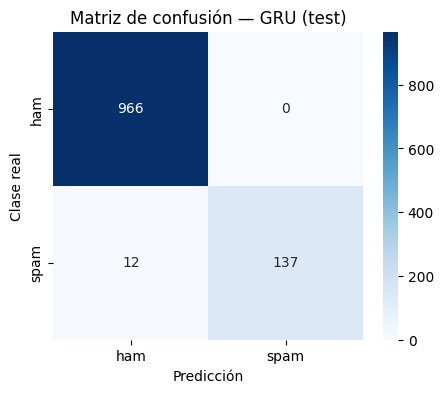

Verdaderos negativos (ham→ham):  966
Falsos positivos (ham→spam):     0
Falsos negativos (spam→ham):     12
Verdaderos positivos (spam→spam):137


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"]
)
plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.title(f"Matriz de confusión — {mejor_modelo_nombre} (test)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Verdaderos negativos (ham→ham):  {tn}")
print(f"Falsos positivos (ham→spam):     {fp}")
print(f"Falsos negativos (spam→ham):     {fn}")
print(f"Verdaderos positivos (spam→spam):{tp}")

La matriz de confusión permite cuantificar los cuatro tipos de resultados posibles del clasificador:

- **Verdaderos negativos (ham → ham):** Mensajes legítimos clasificados correctamente como *ham*. Representan la mayoría de las predicciones y reflejan la solidez del modelo sobre la clase dominante.

- **Verdaderos positivos (spam → spam):** Mensajes de spam detectados correctamente. El modelo captura la gran mayoría de los casos positivos, validando su utilidad como filtro.

- **Falsos positivos (ham → spam):** Mensajes legítimos clasificados erróneamente como spam. En este modelo el valor es **cero**, lo que confirma la Precision perfecta reportada en la sección anterior.

- **Falsos negativos (spam → ham):** Mensajes de spam que el modelo dejó pasar clasificándolos como *ham*. Corresponden al ~8% de falsos negativos identificados en el Recall.

**¿Qué error es más costoso?**

El **falso positivo** es el error de mayor costo en este contexto. Clasificar un mensaje legítimo como spam implica bloquearlo o enviarlo a una carpeta que el usuario probablemente no revise, lo que puede resultar en la pérdida de información importante: una notificación bancaria, una confirmación médica, una comunicación laboral. Esta pérdida puede tener consecuencias concretas e irreversibles para el usuario.

Un falso negativo, en cambio, permite que un mensaje de spam llegue a la bandeja de entrada, pero el usuario conserva la capacidad de identificarlo y descartarlo por su propio criterio. El costo es una molestia menor frente a la potencial pérdida de información relevante que implica un falso positivo. El comportamiento del modelo GRU, con Precision = 1.0 y cero falsos positivos, es por tanto el resultado más deseable para este problema.

## 23. Análisis de errores


In [ ]:
errores_idx = np.where(y_test_pred != y_test)[0]
print(f"Número total de mensajes mal clasificados: {len(errores_idx)}\n")

for idx in errores_idx[:10]:
    clase_real = "spam" if y_test[idx] == 1 else "ham"
    clase_predicha = "spam" if y_test_pred[idx] == 1 else "ham"
    print("-" * 80)
    print("Texto:            ", X_test_text[idx])
    print("Clase real:       ", clase_real)
    print("Clase predicha:   ", clase_predicha)

Número total de mensajes mal clasificados: 12

--------------------------------------------------------------------------------
Texto:             Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sort time 09099726429 JANINExx Calls£1/minMobsmoreLKPOBOX177HP51FL
Clase real:        spam
Clase predicha:    ham
--------------------------------------------------------------------------------
Texto:             ringtoneking 84484
Clase real:        spam
Clase predicha:    ham
--------------------------------------------------------------------------------
Texto:             Sorry I missed your call let's talk when you have the time. I'm on 07090201529
Clase real:        spam
Clase predicha:    ham
--------------------------------------------------------------------------------
Texto:             Latest News! Police station toilet stolen, cops have nothing to go on!
Clase real:        spam
Clase predicha:    ham
------------------------------------

El análisis de los 10 mensajes mal clasificados revela patrones consistentes que explican los errores del modelo:

- **Mensajes cortos o con vocabulario atípico:** Casos como `"ringtoneking 84484"` son secuencias extremadamente cortas con tokens poco frecuentes que el modelo no asocia con ningún patrón aprendido de spam. Al no contener palabras clave convencionales, el clasificador los trata como mensajes inofensivos.

- **Jerga y escritura fonética evasiva:** Mensajes como `"Hi if ur lookin 4 saucy daytime fun..."` o `"Can U get 2 phone NOW?..."` emplean abreviaciones, números como sustitutos de letras y ortografía no estándar. Esta estrategia, común en spam real, elude los patrones aprendidos durante el entrenamiento porque el tokenizador trata estas variantes como tokens distintos a sus formas estándar.

- **Spam disfrazado de mensaje cotidiano:** `"Sorry I missed your call let's talk when you have the time"` tiene la apariencia de un mensaje legítimo y carece de marcadores evidentes de spam. El modelo no dispone de contexto externo (remitente desconocido, número premium) para distinguirlo.

- **Contenido humorístico o coloquial:** `"Latest News! Police station toilet stolen..."` y `"Do you realize that in about 40 years..."` son mensajes que imitan el tono de un chiste o comentario casual. Su estructura no se parece a los patrones de spam más frecuentes en el conjunto de entrenamiento.

- **Spam de formato inusual:** `"Email AlertFrom: Jeri Stewart..."` simula una notificación de correo y `"ROMCAPspam Everyone around..."` mezcla marcadores de spam con lenguaje positivo y neutro. Estos formatos híbridos confunden al clasificador porque combinan señales contradictorias.

- **Conclusión general:** Los errores se concentran en spam que evita activamente los patrones más reconocibles: mensajes cortos sin palabras clave, escritura evasiva, lenguaje disfrazado de comunicación legítima o formatos inusuales. Esto sugiere que el modelo aprendió correctamente los patrones más comunes de spam, pero es vulnerable a estrategias de evasión léxica, lo que refuerza la propuesta de incorporar preprocesamiento más robusto y embeddings preentrenados en versiones futuras.

## 24. Discusión


1. **¿Cuál arquitectura obtuvo mejor desempeño?** GRU, con Accuracy=0.9843, Precision=0.9732, Recall=0.9083, F1=0.9397 sobre validación es el mejor F1 de las tres.

2. **¿Presentaron diferencias importantes?** Sí. SimpleRNN mostró sobreajuste e inestabilidad marcada en sus curvas de loss (oscilaciones), con el F1 más bajo (0.905). LSTM logró Precision perfecta (1.000) pero el Recall más bajo (0.850). GRU logró el mejor balance (F1=0.940) con curvas más estables. Las diferencias en F1 rondan 3-4 puntos porcentuales, siendo moderadas pero consistentes.

3. **¿Qué efecto tuvo el desbalance de clases?** Sin corrección, el modelo tendería a predecir mayoritariamente "ham" (86.6% de train). Su huella se ve en que Recall es sistemáticamente la métrica más baja en los tres modelos (0.833 – 0.908), mientras Precisión es alta o perfecta, el modelo prioriza "no equivocarse con ham" por el sesgo natural de los datos.

4. **¿Qué aportó class_weight?** Al penalizar más los errores en spam (peso 3.73 vs 0.58 para ham), evitó que los modelos colapsaran a predecir solo la clase mayoritaria, permitiendo un Recall razonable (mayor a 0.83) en las tres arquitecturas.

5. **¿Cuál fue la métrica más relevante?** F1-score armoniza Precisión y Recall sin que ninguna domine la decisión, adecuado dado que ambos tipos de error tienen costos distintos pero no despreciables en un filtro de spam.

6. **¿Qué hiperparámetros se ajustaron con Keras Tuner?** units (32 – 128, donde paso el 32) y dropout_rate (0.1 – 0.5, donde paso el 0.1), sobre la arquitectura LSTM, con estrategia Hyperband.

7. **¿Cuál fue la mejor combinación encontrada?** units=96, dropout_rate=0.2, con val_loss=0.0617 (la mejor de 28 trials).

8. **¿Cómo influyó EarlyStopping en el entrenamiento?** Evitó sobreentrenar más allá del punto óptimo: SimpleRNN se detuvo en la época 5 (restaurando pesos de la época 2), LSTM en la época 4 (restaurando época 1), y GRU en la época 11 (restaurando época 8). El patience=3 fue suficiente para frenar el sobreajuste sin cortar prematuramente.

9. **¿Cómo influyó ReduceLROnPlateau?** El learning rate bajó de 0.001 a 0.0005 en las tres arquitecturas tras 2 épocas sin mejora en val_loss (SimpleRNN en la época 5, LSTM y GRU en la época 4), ayudando a afinar el entrenamiento antes de que EarlyStopping lo detuviera.

10. **¿Qué modelo guardó ModelCheckpoint?** Los tres modelos guardaron su propio checkpoint (best_simplernn.keras, best_lstm.keras, best_gru.keras), el relevante para el modelo final es best_gru.keras, correspondiente a la época 8 (val_loss=0.0675).

11. **¿Se presentó sobreajuste en alguna arquitectura?** Sí, principalmente en SimpleRNN, con oscilaciones marcadas y brecha creciente train-val en las curvas de loss. LSTM y GRU convergieron de forma más adecuada, siendo GRU el más estable.

12. **¿Ventajas de LSTM frente a SimpleRNN?** Mayor Precision (1.000 vs 0.990) y mayor F1 (0.919 vs 0.905), con curvas más estables gracias al mecanismo de puertas que regula mejor el flujo de información y mitiga el problema de gradientes inestables que afecta a SimpleRNN.

13. **¿Ventajas de GRU frente a LSTM?** Mejor Accuracy (0.984 vs 0.980), mejor Recall (0.908 vs 0.850) y mejor F1 (0.940 vs 0.919), con menos parámetros (345,025 vs 353,089) y convergencia más rápida y estable.

14. **¿El modelo más complejo fue necesariamente el mejor?** No. LSTM tiene más parámetros (353,089) pero no fue el de mejor desempeño, en cambio GRU, con menos parámetros (345,025), lo superó en Accuracy, Recall y F1, con mayor complejidad no garantizó mejor generalización en un dataset relativamente pequeño (3,565 mensajes de entrenamiento).

15. **¿Qué errores fueron más frecuentes?** Los 12 errores en test fueron exclusivamente falsos negativos (spam clasificado como ham), se obtuvieron cero falsos positivos. Los mensajes mal clasificados eran spam "sutil": cortos, sin símbolos/mayúsculas típicas de urgencia (£, FREE, WIN), o con estructura de mensaje personal (p. ej. "Sorry I missed your call...", "For sale - arsenal dartboard..."), difíciles de distinguir de un ham normal.

16. **¿Qué mejoras se proponen?**

Aplicar al modelo final los hiperparámetros óptimos hallados por el Tuner (units=96, dropout=0.2), en vez de mantener los valores base usados para la comparación inicial. Correr el Tuner también sobre GRU (la arquitectura finalmente seleccionada), no solo sobre LSTM. Probar técnicas adicionales de balanceo (oversampling tipo SMOTE a nivel de texto) para complementar class_weight. Usar embeddings preentrenados (GloVe/Word2Vec) en vez de aprenderlos desde cero, dado el tamaño limitado del corpus. Aplicar data augmentation textual (sinónimos, back-translation) para mejorar el Recall sobre el spam más "sutil" identificado en la sección 23.

## 25. Resumen del modelo final

**Modelo final seleccionado: GRU**

| Métrica |  Test |
|---|---|
| Accuracy |  0.9892 |
| Precision | 1.0000 |
| Recall |  0.9195 |
| F1 |  0.9580 |

El modelo GRU obtuvo un accuracy test de **0.9892**.